# Load Libraries and Data

In [2]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms

from utils.neural_networks_utils import *
from utils.random_search_utils import random_search, get_best_hyper_parameters, run_random_search
from utils.data_loaders import load_dataset, load_images
from utils.utils import *

import os
import pandas as pd

from sklearn.model_selection import RepeatedKFold
from sklearn.preprocessing import StandardScaler

import warnings
import numpy as np
import importlib

import copy
from skorch.callbacks import EarlyStopping
from torchvision.models.feature_extraction import create_feature_extractor, get_graph_node_names
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")

torch.manual_seed(42)
np.random.seed(42)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [3]:
# Check and create directories for saving processed data
cur_dir = os.getcwd()
model_save_loc_dcnn = os.path.join(cur_dir, "models/DCNN")
check_create_directory(model_save_loc_dcnn)
result_save_loc_dcnn = os.path.join(cur_dir, "results/DCNN")
check_create_directory(result_save_loc_dcnn)

# Check and create directories for saving processed data
cur_dir = os.getcwd()
model_save_loc_c_dcnn = os.path.join(cur_dir, "models/C-DCNN")
check_create_directory(model_save_loc_c_dcnn)
result_save_loc_c_dcnn = os.path.join(cur_dir, "results/C-DCNN")
check_create_directory(result_save_loc_c_dcnn)



Directory already exists: /home/fdeniz2/ML Paper/models/DCNN
Directory already exists: /home/fdeniz2/ML Paper/results/DCNN
Directory already exists: /home/fdeniz2/ML Paper/models/C-DCNN
Directory already exists: /home/fdeniz2/ML Paper/results/C-DCNN


In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

csv_file = "/home/fdeniz2/all_data/combined_visual_features.csv"
img_dir = "/home/fdeniz2/all_data/images_anonymized"
# check this only affect adata?? something is wrong with it!!
mean_data = pd.read_csv(csv_file) 
fix_names_dataframe(mean_data)
mean_data_only_affect = mean_data[["image", "valence", "approach", "tense", "energetic"]] 

scaler = StandardScaler()

# Scale all visual features
#mean_data[mean_data.columns.difference(["image", "Unnamed: 0", "room_type", "valence", "tense", "energetic", "approach"])]= scaler.fit_transform(mean_data[mean_data.columns.difference(["image", "Unnamed: 0", "room_type","valence", "tense", "energetic", "approach"])])
number_of_visual_features =  len(mean_data[mean_data.columns.difference(["image", "valence", "Unnamed: 0", "room_type", "approach", "tense", "energetic"])].columns)

# Transformation for images
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                          std=[0.229, 0.224, 0.225])])
# Parameter grid for random search
param_grid = {
    'net__lr': [0.01,0.001,0.0001],
    'net__optimizer__weight_decay': [0.01,0.001,0.0001],
    'net__module__drop_out_rate': [0.1,0.2,0.3,0.4, 0.5],
    'net__batch_size':[32,64,128,256]
}
random_state = 42
repeated_k_fold = RepeatedKFold(n_splits=5, n_repeats=6, random_state=random_state)
# Network Paramaters
n_epochs = 1000
patience = 10

#### Extract DCNN embeddings

In [4]:
# Extract Embeddings of DCNN
convxnet_loaded = load_convx(device)
# Load Data
dataset = load_images(img_dir, transform = transform, multiple_folder =  True)
dataset = DataLoader(dataset, batch_size=216, shuffle=False, num_workers=4, pin_memory=True)

return_nodes = {"classifier.1": "layer"}

embeddings = extract_embeddings(convxnet_loaded, return_nodes, dataset, device)
all_outputs = pd.merge(embeddings, mean_data_only_affect, on = "image")

combined_outputs = pd.merge(embeddings, mean_data[mean_data.columns.difference(["room_type", "Unnamed: 0"])], on = "image")

combined_outputs.columns = combined_outputs.columns.astype(str)
all_outputs.columns = all_outputs.columns.astype(str)

# Valence

### DCNN

#### Random Search

In [5]:
import importlib
import utils
import utils.random_search_utils

importlib.reload(utils.random_search_utils)
random_research_results_dcnn_loc = "./results/DCNN/random_search_dcnn.csv"
lr, wd, dp, batch_size = run_random_search(random_research_results_dcnn_loc, all_outputs, "valence", repeated_k_fold, param_grid,
                                           number_of_visual_features, prediction_head, random_state)

Using stored hyperparameters


#### Final Model

In [6]:
k_folds_results_valence = train_model_cv(model_function = prediction_head,mean_data=all_outputs,repeated_k_fold=repeated_k_fold,target="valence", 
                                         lr=lr, wd=wd, dp=dp, batch=batch_size, number_of_visual_features=768, n_epochs=n_epochs, patience=patience, 
                                         device=device, save=True, save_loc=model_save_loc_dcnn)


Training fold 0
Best model updated
Epoch [1/1000] Train Loss: 3.88469 | Test Loss: 2.89107 | MAE: 2.89107 | R2: -10.75032 | Patience: 0/10 | LR: 0.00014500
Best model updated
Epoch [2/1000] Train Loss: 2.72733 | Test Loss: 1.80368 | MAE: 1.80368 | R2: -4.10645 | Patience: 0/10 | LR: 0.00019000
Best model updated
Epoch [3/1000] Train Loss: 1.85384 | Test Loss: 1.21650 | MAE: 1.21650 | R2: -1.53256 | Patience: 0/10 | LR: 0.00023500
Best model updated
Epoch [4/1000] Train Loss: 1.29197 | Test Loss: 0.89008 | MAE: 0.89008 | R2: -0.46683 | Patience: 0/10 | LR: 0.00028000
Best model updated
Epoch [5/1000] Train Loss: 0.96509 | Test Loss: 0.73190 | MAE: 0.73190 | R2: -0.05119 | Patience: 0/10 | LR: 0.00032500
Best model updated
Epoch [6/1000] Train Loss: 0.78854 | Test Loss: 0.67346 | MAE: 0.67346 | R2: 0.10248 | Patience: 0/10 | LR: 0.00037000
Best model updated
Epoch [7/1000] Train Loss: 0.69086 | Test Loss: 0.64531 | MAE: 0.64531 | R2: 0.16612 | Patience: 0/10 | LR: 0.00041500
Best model 

In [7]:
performance_valence = performance_model_cv(model_function = prediction_head, mean_data=all_outputs, repeated_k_fold=repeated_k_fold,target="valence",
                                           device=device, n_features=768, drop_out_rate=dp, model_dir=model_save_loc_dcnn, batch_size=256, scale=True, 
                                           save=True, save_loc=os.path.join(result_save_loc_dcnn, "dcnn_valence.csv"), multiple_folder = True)

Evaluating fold 0
Evaluating fold 1
Evaluating fold 2
Evaluating fold 3
Evaluating fold 4
Evaluating fold 5
Evaluating fold 6
Evaluating fold 7
Evaluating fold 8
Evaluating fold 9
Evaluating fold 10
Evaluating fold 11
Evaluating fold 12
Evaluating fold 13
Evaluating fold 14
Evaluating fold 15
Evaluating fold 16
Evaluating fold 17
Evaluating fold 18
Evaluating fold 19
Evaluating fold 20
Evaluating fold 21
Evaluating fold 22
Evaluating fold 23
Evaluating fold 24
Evaluating fold 25
Evaluating fold 26
Evaluating fold 27
Evaluating fold 28
Evaluating fold 29


### C-DCNN

##### Random Search

In [8]:
random_research_results_cdcnn_loc = "./results/C-DCNN/random_search_cdcnn.csv"
lr, wd, dp, batch_size = run_random_search(random_research_results_cdcnn_loc, combined_outputs, "valence", repeated_k_fold, param_grid,
                                           number_of_visual_features+768, prediction_head, random_state)

Using stored hyperparameters


##### Final Models

In [9]:
k_folds_results_valence = train_model_cv(model_function = prediction_head,mean_data=combined_outputs,repeated_k_fold=repeated_k_fold,target="valence",
    lr=lr,wd=wd,dp=dp,batch=batch_size, number_of_visual_features=768 + number_of_visual_features, n_epochs=n_epochs, patience=patience,
    device=device, save=True, save_loc=model_save_loc_c_dcnn)


Training fold 0
Best model updated
Epoch [1/1000] Train Loss: 4.18793 | Test Loss: 3.29749 | MAE: 3.29749 | R2: -13.98512 | Patience: 0/10 | LR: 0.00014500
Best model updated
Epoch [2/1000] Train Loss: 3.11107 | Test Loss: 2.20291 | MAE: 2.20291 | R2: -6.23374 | Patience: 0/10 | LR: 0.00019000
Best model updated
Epoch [3/1000] Train Loss: 2.22380 | Test Loss: 1.54048 | MAE: 1.54048 | R2: -2.85677 | Patience: 0/10 | LR: 0.00023500
Best model updated
Epoch [4/1000] Train Loss: 1.61318 | Test Loss: 1.13128 | MAE: 1.13128 | R2: -1.23758 | Patience: 0/10 | LR: 0.00028000
Best model updated
Epoch [5/1000] Train Loss: 1.20347 | Test Loss: 0.87364 | MAE: 0.87364 | R2: -0.42991 | Patience: 0/10 | LR: 0.00032500
Best model updated
Epoch [6/1000] Train Loss: 0.94194 | Test Loss: 0.74136 | MAE: 0.74136 | R2: -0.06933 | Patience: 0/10 | LR: 0.00037000
Best model updated
Epoch [7/1000] Train Loss: 0.79188 | Test Loss: 0.68714 | MAE: 0.68714 | R2: 0.07143 | Patience: 0/10 | LR: 0.00041500
Best model

In [10]:
performance_valence = performance_model_cv(model_function = prediction_head, mean_data=combined_outputs, repeated_k_fold=repeated_k_fold, target="valence",
                                        device=device, n_features=768 + number_of_visual_features, drop_out_rate=0.5, model_dir=model_save_loc_c_dcnn, batch_size=256, 
                                           scale=True, save=True, save_loc=os.path.join(result_save_loc_c_dcnn, "c_dcnn_valence.csv"), multiple_folder = True)

Evaluating fold 0
Evaluating fold 1
Evaluating fold 2
Evaluating fold 3
Evaluating fold 4
Evaluating fold 5
Evaluating fold 6
Evaluating fold 7
Evaluating fold 8
Evaluating fold 9
Evaluating fold 10
Evaluating fold 11
Evaluating fold 12
Evaluating fold 13
Evaluating fold 14
Evaluating fold 15
Evaluating fold 16
Evaluating fold 17
Evaluating fold 18
Evaluating fold 19
Evaluating fold 20
Evaluating fold 21
Evaluating fold 22
Evaluating fold 23
Evaluating fold 24
Evaluating fold 25
Evaluating fold 26
Evaluating fold 27
Evaluating fold 28
Evaluating fold 29


# Tense Arousal

#### DCNN

##### Random Search

In [11]:
random_research_results_dcnn_loc = "./results/DCNN/random_search_dcnn.csv"
lr, wd, dp, batch_size = run_random_search(random_research_results_dcnn_loc, all_outputs, "tense", repeated_k_fold, param_grid,
                                           number_of_visual_features, prediction_head, random_state)

Running random search


##### Model Training

In [12]:
k_folds_results_tense_dcnn = train_model_cv(model_function = prediction_head,mean_data=all_outputs,repeated_k_fold=repeated_k_fold,target="tense",lr=lr,
                                            wd=wd, dp=dp, batch=batch_size, number_of_visual_features=768, n_epochs=n_epochs, patience=patience, device=device,
                                            save=True, save_loc=model_save_loc_dcnn)


Training fold 0
Best model updated
Epoch [1/1000] Train Loss: 3.01947 | Test Loss: 2.10210 | MAE: 2.10210 | R2: -4.91015 | Patience: 0/10 | LR: 0.00014500
Best model updated
Epoch [2/1000] Train Loss: 1.90177 | Test Loss: 1.08587 | MAE: 1.08587 | R2: -1.16962 | Patience: 0/10 | LR: 0.00019000
Best model updated
Epoch [3/1000] Train Loss: 1.05584 | Test Loss: 0.75116 | MAE: 0.75116 | R2: -0.09413 | Patience: 0/10 | LR: 0.00023500
Best model updated
Epoch [4/1000] Train Loss: 0.72235 | Test Loss: 0.74468 | MAE: 0.74468 | R2: 0.06535 | Patience: 0/10 | LR: 0.00028000
Best model updated
Epoch [5/1000] Train Loss: 0.67693 | Test Loss: 0.73237 | MAE: 0.73237 | R2: 0.13836 | Patience: 0/10 | LR: 0.00032500
Best model updated
Epoch [6/1000] Train Loss: 0.62930 | Test Loss: 0.61539 | MAE: 0.61539 | R2: 0.34778 | Patience: 0/10 | LR: 0.00037000
Best model updated
Epoch [7/1000] Train Loss: 0.56906 | Test Loss: 0.53328 | MAE: 0.53328 | R2: 0.46235 | Patience: 0/10 | LR: 0.00041500
Best model upd

In [13]:
performance_tense_dcnn = performance_model_cv(model_function = prediction_head, mean_data=all_outputs,repeated_k_fold=repeated_k_fold, target="tense", 
                                              device=device, n_features=768, drop_out_rate=0.5, model_dir=model_save_loc_dcnn, batch_size=256,
                                              scale=True, save=True, save_loc=os.path.join(result_save_loc_dcnn, "dcnn_tense.csv"), multiple_folder = True)

Evaluating fold 0
Evaluating fold 1
Evaluating fold 2
Evaluating fold 3
Evaluating fold 4
Evaluating fold 5
Evaluating fold 6
Evaluating fold 7
Evaluating fold 8
Evaluating fold 9
Evaluating fold 10
Evaluating fold 11
Evaluating fold 12
Evaluating fold 13
Evaluating fold 14
Evaluating fold 15
Evaluating fold 16
Evaluating fold 17
Evaluating fold 18
Evaluating fold 19
Evaluating fold 20
Evaluating fold 21
Evaluating fold 22
Evaluating fold 23
Evaluating fold 24
Evaluating fold 25
Evaluating fold 26
Evaluating fold 27
Evaluating fold 28
Evaluating fold 29


### C-DCNN

##### Random Search

In [14]:
random_research_results_cdcnn_loc = "./results/C-DCNN/random_search_cdcnn.csv"
lr, wd, dp, batch_size = run_random_search(random_research_results_cdcnn_loc, combined_outputs, "tense", repeated_k_fold, param_grid,
                                           number_of_visual_features+768, prediction_head, random_state)

Running random search


#### Final Model

In [15]:
k_folds_results_valence = train_model_cv(model_function = prediction_head,mean_data=combined_outputs,repeated_k_fold=repeated_k_fold,target="tense",
    lr=lr,wd=wd,dp=dp,batch=batch_size, number_of_visual_features=768 + number_of_visual_features, n_epochs=n_epochs, patience=patience,
    device=device, save=True, save_loc=model_save_loc_c_dcnn)


Training fold 0
Best model updated
Epoch [1/1000] Train Loss: 3.10001 | Test Loss: 2.14559 | MAE: 2.14559 | R2: -5.16056 | Patience: 0/10 | LR: 0.00014500
Best model updated
Epoch [2/1000] Train Loss: 1.96333 | Test Loss: 1.11673 | MAE: 1.11673 | R2: -1.19328 | Patience: 0/10 | LR: 0.00019000
Best model updated
Epoch [3/1000] Train Loss: 1.12524 | Test Loss: 0.74056 | MAE: 0.74056 | R2: -0.08868 | Patience: 0/10 | LR: 0.00023500
Best model updated
Epoch [4/1000] Train Loss: 0.74525 | Test Loss: 0.69461 | MAE: 0.69461 | R2: 0.13140 | Patience: 0/10 | LR: 0.00028000
Epoch [5/1000] Train Loss: 0.66215 | Test Loss: 0.71033 | MAE: 0.71033 | R2: 0.16689 | Patience: 1/10 | LR: 0.00032500
Best model updated
Epoch [6/1000] Train Loss: 0.63068 | Test Loss: 0.63857 | MAE: 0.63857 | R2: 0.31035 | Patience: 0/10 | LR: 0.00037000
Best model updated
Epoch [7/1000] Train Loss: 0.57791 | Test Loss: 0.54750 | MAE: 0.54750 | R2: 0.44550 | Patience: 0/10 | LR: 0.00041500
Best model updated
Epoch [8/1000]

In [16]:
performance_valence = performance_model_cv(model_function = prediction_head, mean_data=combined_outputs, repeated_k_fold=repeated_k_fold, target="valence",
                                        device=device, n_features=768 + number_of_visual_features, drop_out_rate=0.5, model_dir=model_save_loc_c_dcnn, batch_size=256, 
                                           scale=True, save=True, save_loc=os.path.join(result_save_loc_c_dcnn, "c_dcnn_tense.csv"), multiple_folder = True)

Evaluating fold 0
Evaluating fold 1
Evaluating fold 2
Evaluating fold 3
Evaluating fold 4
Evaluating fold 5
Evaluating fold 6
Evaluating fold 7
Evaluating fold 8
Evaluating fold 9
Evaluating fold 10
Evaluating fold 11
Evaluating fold 12
Evaluating fold 13
Evaluating fold 14
Evaluating fold 15
Evaluating fold 16
Evaluating fold 17
Evaluating fold 18
Evaluating fold 19
Evaluating fold 20
Evaluating fold 21
Evaluating fold 22
Evaluating fold 23
Evaluating fold 24
Evaluating fold 25
Evaluating fold 26
Evaluating fold 27
Evaluating fold 28
Evaluating fold 29


# Energetic Arousal

### DCNN 

##### Random Search

In [17]:
random_research_results_dcnn_loc = "./results/DCNN/random_search_dcnn.csv"
lr, wd, dp, batch_size = run_random_search(random_research_results_dcnn_loc, all_outputs, "energetic", repeated_k_fold, param_grid,
                                           number_of_visual_features, prediction_head, random_state)

Running random search


#### Final Model

In [18]:
k_folds_results_tense_dcnn = train_model_cv(model_function = prediction_head,mean_data=all_outputs,repeated_k_fold=repeated_k_fold,target="energetic",lr=lr,
                                            wd=wd, dp=dp, batch=batch_size, number_of_visual_features=768, n_epochs=n_epochs, patience=patience, device=device,
                                            save=True, save_loc=model_save_loc_dcnn)


Training fold 0
Best model updated
Epoch [1/1000] Train Loss: 4.58699 | Test Loss: 4.23295 | MAE: 4.23295 | R2: -18.42702 | Patience: 0/10 | LR: 0.00001450
Best model updated
Epoch [2/1000] Train Loss: 4.14891 | Test Loss: 3.59020 | MAE: 3.59020 | R2: -13.25181 | Patience: 0/10 | LR: 0.00001900
Best model updated
Epoch [3/1000] Train Loss: 3.59850 | Test Loss: 2.88875 | MAE: 2.88875 | R2: -8.56628 | Patience: 0/10 | LR: 0.00002350
Best model updated
Epoch [4/1000] Train Loss: 2.99436 | Test Loss: 2.24475 | MAE: 2.24475 | R2: -5.12621 | Patience: 0/10 | LR: 0.00002800
Best model updated
Epoch [5/1000] Train Loss: 2.42986 | Test Loss: 1.77735 | MAE: 1.77735 | R2: -2.96487 | Patience: 0/10 | LR: 0.00003250
Best model updated
Epoch [6/1000] Train Loss: 2.00168 | Test Loss: 1.47355 | MAE: 1.47355 | R2: -1.73957 | Patience: 0/10 | LR: 0.00003700
Best model updated
Epoch [7/1000] Train Loss: 1.67867 | Test Loss: 1.26580 | MAE: 1.26579 | R2: -1.01559 | Patience: 0/10 | LR: 0.00004150
Best mod

In [19]:
performance_tense_dcnn = performance_model_cv(model_function = prediction_head, mean_data=all_outputs,repeated_k_fold=repeated_k_fold, target="energetic", 
                                              device=device, n_features=768, drop_out_rate=0.5, model_dir=model_save_loc_dcnn, batch_size=256,
                                              scale=True, save=True, save_loc=os.path.join(result_save_loc_dcnn, "dcnn_energetic.csv"), multiple_folder = True)

Evaluating fold 0
Evaluating fold 1
Evaluating fold 2
Evaluating fold 3
Evaluating fold 4
Evaluating fold 5
Evaluating fold 6
Evaluating fold 7
Evaluating fold 8
Evaluating fold 9
Evaluating fold 10
Evaluating fold 11
Evaluating fold 12
Evaluating fold 13
Evaluating fold 14
Evaluating fold 15
Evaluating fold 16
Evaluating fold 17
Evaluating fold 18
Evaluating fold 19
Evaluating fold 20
Evaluating fold 21
Evaluating fold 22
Evaluating fold 23
Evaluating fold 24
Evaluating fold 25
Evaluating fold 26
Evaluating fold 27
Evaluating fold 28
Evaluating fold 29


### C-DCNN

##### Random Search

In [20]:
random_research_results_cdcnn_loc = "./results/C-DCNN/random_search_cdcnn.csv"
lr, wd, dp, batch_size = run_random_search(random_research_results_cdcnn_loc, combined_outputs, "energetic", repeated_k_fold, param_grid,
                                           number_of_visual_features+768, prediction_head, random_state)

Running random search


#### Final Model

In [ ]:
k_folds_results_valence = train_model_cv(model_function = prediction_head,mean_data=combined_outputs,repeated_k_fold=repeated_k_fold,target="energetic",
    lr=lr,wd=wd,dp=dp,batch=batch_size, number_of_visual_features=768 + number_of_visual_features, n_epochs=n_epochs, patience=patience,
    device=device, save=True, save_loc=model_save_loc_c_dcnn)


Training fold 0
Best model updated
Epoch [1/1000] Train Loss: 4.20923 | Test Loss: 3.82191 | MAE: 3.82191 | R2: -15.37767 | Patience: 0/10 | LR: 0.00001450
Best model updated
Epoch [2/1000] Train Loss: 3.76257 | Test Loss: 3.21366 | MAE: 3.21366 | R2: -10.95696 | Patience: 0/10 | LR: 0.00001900
Best model updated
Epoch [3/1000] Train Loss: 3.23599 | Test Loss: 2.58942 | MAE: 2.58942 | R2: -7.13827 | Patience: 0/10 | LR: 0.00002350
Best model updated
Epoch [4/1000] Train Loss: 2.70243 | Test Loss: 2.07169 | MAE: 2.07169 | R2: -4.40653 | Patience: 0/10 | LR: 0.00002800
Best model updated
Epoch [5/1000] Train Loss: 2.23196 | Test Loss: 1.70141 | MAE: 1.70141 | R2: -2.67072 | Patience: 0/10 | LR: 0.00003250
Best model updated
Epoch [6/1000] Train Loss: 1.85966 | Test Loss: 1.42297 | MAE: 1.42297 | R2: -1.56376 | Patience: 0/10 | LR: 0.00003700
Best model updated
Epoch [7/1000] Train Loss: 1.56136 | Test Loss: 1.20092 | MAE: 1.20091 | R2: -0.81874 | Patience: 0/10 | LR: 0.00004150
Best mod

In [ ]:
performance_valence = performance_model_cv(model_function = prediction_head, mean_data=combined_outputs, repeated_k_fold=repeated_k_fold, target="valence",
                                        device=device, n_features=768 + number_of_visual_features, drop_out_rate=0.5, model_dir=model_save_loc_c_dcnn, batch_size=256, 
                                           scale=True, save=True, save_loc=os.path.join(result_save_loc_c_dcnn, "c_dcnn_energetic.csv"), multiple_folder = True)

# Exploring Embeddings

In [25]:
from sklearn.linear_model import RidgeCV, Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from utils.utils import fit_models_cross_validation
import importlib
import utils.utils
importlib.reload(utils.utils)
from utils.utils import fit_models_cross_validation

# Extract Embeddings of DCNN
convxnet_loaded = load_convx(device)
# Load Data
dataset = load_images(img_dir, transform = transform, multiple_folder =  True)
dataset = DataLoader(dataset, batch_size=216, shuffle=False, num_workers=4, pin_memory=True)

#return_nodes = {"classifier.1": "layer"}
return_nodes = {"avgpool": "layer"}

embeddings = extract_embeddings(convxnet_loaded, return_nodes, dataset, device)

all_outputs = pd.merge(embeddings, mean_data[["image","valence", "tense", "energetic", "approach"]], on = "image")

combined_outputs = pd.merge(embeddings, mean_data[["image","valence", "tense", "energetic", "approach"]], on = "image")

combined_outputs.columns = combined_outputs.columns.astype(str)
all_outputs.columns = all_outputs.columns.astype(str)

feature_columns = mean_data.columns.difference(["valence", "Unnamed: 0", "room_type", "image", "approach", "tense", "energetic"])

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(random_state = 42))
])

X = all_outputs[all_outputs.columns.difference(["valence", "Unnamed: 0", "room_type", "image", "approach", "tense", "energetic"])]

param_grid = {
    "ridge__alpha": np.logspace(-1, 6, 50)
}

scores = {"feature_name":[], "R2":[], "R2_var":[]}
for feature_name in feature_columns:
    y = mean_data[feature_name]

    grid = GridSearchCV(pipeline, param_grid = param_grid, scoring = "r2", n_jobs = -1)
    grid.fit(X, y)
    
    scores_r2, _, _ = fit_models_cross_validation(X, y, grid.best_estimator_, repeated_k_fold, None, None, False)
    scores["feature_name"].append(feature_name)
    scores["R2"].append(np.mean(scores_r2["Rsquared"]))
    scores["R2_var"].append(np.std(scores_r2["Rsquared"]))
    
scores = pd.DataFrame.from_dict(scores)   

# Rearrange order of columns for plotting.
column_order = ['Mean Hue', 'Mean Saturation', 'Mean Brightness', 'SD Saturation', 'SD Hue', 'SD Brightness', 'Fourier Slope', 
            'Fourier Sigma', 'Edge Density', 'Entropy', '1st order edge density', 'Table', 'Swivel Chair', 'Chair', 'Lamp', 
            'Sink', 'Stove', 'Bed', 'Computer', 'Cushion', 'Desk', 'Light', 'Cabinet', 'Painting', 'Sofa', 'Window', 
            'Open area', 'Semi-enclosed area', 'Far-away horizon', 'Enclosed area', 'Symmetry up-down', 'Symmetry left-right', 
            'Contour Curvature', 'Contour Length', 'Contour Orientation', 'Reading', 'Using tools', 'Exercise', 'Playing', 
            'Working', 'Cleaning', 'Gaming', 'Socializing', 'Shopping']
# Save scores somewhere!!!!!!!
scores = scores.set_index("feature_name").loc[column_order].reset_index()

Process LokyProcess-17:
Traceback (most recent call last):
  File "/usr/lib/python3.10/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
  File "/usr/lib/python3.10/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
  File "/home/fdeniz2/.local/lib/python3.10/site-packages/joblib/externals/loky/process_executor.py", line 501, in _process_worker
    with worker_exit_lock:
  File "/home/fdeniz2/.local/lib/python3.10/site-packages/joblib/externals/loky/backend/synchronize.py", line 119, in __enter__
    return self._semlock.acquire()
KeyboardInterrupt
Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x7f466cc25900>>
Traceback (most recent call last):
  File "/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py", line 775, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(
KeyboardInterrupt: 

KeyboardInterrupt



In [26]:
from sklearn.linear_model import RidgeCV
from sklearn.metrics import r2_score
from joblib import Parallel, delayed

X_np = X.to_numpy(dtype=np.float64)
Y = data[feature_columns].to_numpy(dtype=np.float64)
assert not np.isnan(Y).any(), "handle NaN targets separately"

alphas = np.logspace(-2, 8, 41)

def run_fold(train_idx, test_idx):
    scaler = StandardScaler().fit(X_np[train_idx])
    Xtr, Xte = scaler.transform(X_np[train_idx]), scaler.transform(X_np[test_idx])
    ridge = RidgeCV(alphas=alphas, alpha_per_target=True).fit(Xtr, Y[train_idx])
    r2 = r2_score(Y[test_idx], ridge.predict(Xte), multioutput="raw_values")
    return r2, ridge.alpha_

results = Parallel(n_jobs=4)(
    delayed(run_fold)(tr, te) for tr, te in repeated_k_fold.split(X_np)
)
r2 = np.array([r for r, _ in results])            # (n_folds, n_features)
chosen = np.array([a for _, a in results])        # (n_folds, n_features)

scores = pd.DataFrame({
    "feature_name": feature_columns,
    "R2": r2.mean(axis=0),
    "R2_sd": r2.std(axis=0),
}).set_index("feature_name").loc[column_order].reset_index()


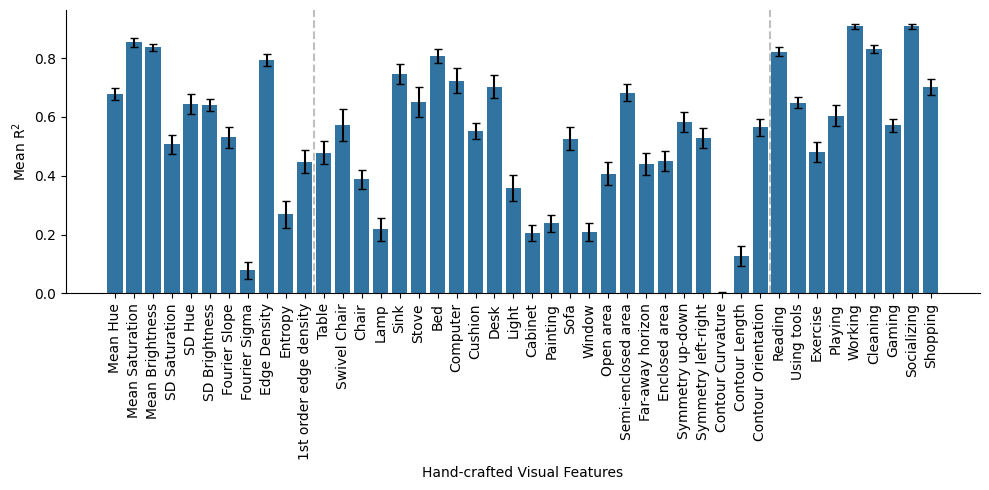

In [33]:
plt.figure(figsize=(10, 5))

sns.barplot(data=scores,x="feature_name",y="R2",errorbar=None)

plt.errorbar(x=np.arange(len(scores)),y=scores["R2"],yerr=scores["R2_sd"],fmt="none",color="black",capsize=3)

plt.axvline(10.5, color="grey", linestyle="--", alpha=0.5)
plt.axvline(34.5, color="grey", linestyle="--", alpha=0.5)

sns.despine() # Remove top and right spine

ax = plt.gca()

ax.set_ylim(0)
plt.xlabel("Hand-crafted Visual Features")
plt.ylabel(r'Mean $\mathregular{R^{2}}$')

plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig(f"/home/fdeniz2/ML Paper/figures/embeddings.svg")